# Model size analysis
Showcase of an abalation experiments to study the effect of model size

## 0 - Setup

In [9]:
%load_ext autoreload
%autoreload 2

import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models  import MerlinHeatQPINN, ClassicalHeatQPINN, MerlinTunableSimple
from src.pde     import HeatEquation, WaveEquation
from src.loss    import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import (
    plot_training_history,
    plot_solution_comparison,
    plot_power_spectrum,
    plot_mode_l2_errors,
    plot_frequency_sweep,
    plot_multi_model_l2_error
)
from src.utils import quantum_outputsize_for_param_match, hilbert_space_dimension, find_matching_hidden_readout
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cpu  |  dtype: torch.float32


## 1 - Frequency Sweep
Train both models on heat equatin over a range of IC frequencies

In [45]:
FEATURE_SIZES_guess = [1, 2, 3, 4]#[2,4,8,16]
HIDDEN_FEATURES = [2,4,8,16]#,16] #16 is the baseline
SEEDS = [42, 666, 69]#, 69, 67, 13]
FREQUENCIES = [0.5, 1.5, 3.0] #3.5 is good, 2.0 is ok, 1.0 is very good

In [46]:
%reload_ext autoreload
print(quantum_outputsize_for_param_match(4,4))
print(hilbert_space_dimension(4))

FEATURE_SIZES, HIDDEN_READOUT = find_matching_hidden_readout(FEATURE_SIZES_guess, ranges=[1,100])

print(FEATURE_SIZES)
print(HIDDEN_READOUT)

            

20.0
35
[[  1   1]
 [  1   2]
 [  1   3]
 ...
 [ 98 100]
 [ 99 100]
 [100 100]]
[1, 2, 3, 4]
[1, 3, 4, 4]


In [55]:
%reload_ext autoreload

full_sweep_results = []
for f in FREQUENCIES:
    sweep_results = {
        "classical": [],
        "qpinn_weights": [],
    }

    for hf in HIDDEN_FEATURES:
        for i in range(len(FEATURE_SIZES)):
            feature_size = FEATURE_SIZES[i]
            hidden_readout = HIDDEN_READOUT[i]

            quantum_output_size = int(
                quantum_outputsize_for_param_match(feature_size, hidden_readout)
            )

            pde = WaveEquation(freq=f, c=1)
            #pde = HeatEquation(freq=f)
            print(f"\n{'='*60}")
            print(
                f"hf={hf}, feature_size={feature_size}, "
                f"hidden_readout={hidden_readout}"
            )

            seed_results = {
                "classical": [],
                "qpinn_weights": [],
            }

            for seed in SEEDS:

                # ---------- QPINN WEIGHTS ----------
                qpinn_weights = MerlinTunableSimple(
                    hidden_feature=hf,
                    feature_size=feature_size,
                    hidden_readout=hidden_readout,
                    pde=pde,
                ).to(device)

                train(
                    model=qpinn_weights,
                    pde=pde,
                    loss_fn=total_loss,
                    log_every=100,
                    seed=seed,
                )

                metrics, _, _, _, _ = evaluate(
                    model=qpinn_weights,
                    pde=pde,
                    device=device,
                    dtype=dtype,
                )

                seed_results["qpinn_weights"].append(metrics["rel_l2"])

                qpinn_num_weights = sum(
                    p.numel() for p in qpinn_weights.parameters()
                    if p.requires_grad
                )

                print(
                    f"QPINN seed={seed:2d}  rel_l2={metrics['rel_l2']:.4e}"
                )

                # ---------- Classical ----------
                classical = ClassicalHeatQPINN(
                    hidden_feature=hf,
                    feature_size=feature_size,
                    quantum_output_size=quantum_output_size,
                    hidden_readout=hidden_readout,
                    pde=pde,
                ).to(device)

                train(
                    model=classical,
                    pde=pde,
                    loss_fn=total_loss,
                    log_every=100,
                    seed=seed,
                )

                metrics, _, _, _, _ = evaluate(
                    model=classical,
                    pde=pde,
                    device=device,
                    dtype=dtype,
                )

                seed_results["classical"].append(metrics["rel_l2"])

                classical_num_weights = sum(
                    p.numel() for p in classical.parameters()
                    if p.requires_grad
                )

                print(
                    f"Classical seed={seed:2d}  rel_l2={metrics['rel_l2']:.4e}"
                )

            # ---------- Store one configuration ----------
            sweep_results["classical"].append({
                "hidden_feature": hf,
                "feature_size": feature_size,
                "hidden_readout": hidden_readout,
                "num_weights": classical_num_weights,
                "rel_l2": seed_results["classical"],
            })

            sweep_results["qpinn_weights"].append({
                "hidden_feature": hf,
                "feature_size": feature_size,
                "hidden_readout": hidden_readout,
                "num_weights": qpinn_num_weights,
                "rel_l2": seed_results["qpinn_weights"],
            })
    full_sweep_results.append({f : sweep_results})
    
#sweep_results = {"classical": [], "qpinn_weights": []} #"qpinn": [],
#for hf in HIDDEN_FEATURES:
#    for j in range(len(FEATURE_SIZES)):
#        feature_size = FEATURE_SIZES[j]
#        hidden_readout = HIDDEN_READOUT[j]
#        quantum_output_size = int(quantum_outputsize_for_param_match(feature_size,hidden_readout))
#
#        #pde = HeatEquation(freq=FREQUENCY)
#        pde = pde = WaveEquation(freq=FREQUENCY,c=1)
#        print(f"\n{'='*60}\nfreq = {FREQUENCY}")
#        seed_results = {"classical": [], "qpinn_weights": []}
#        for i,seed in enumerate(SEEDS):
#    #        # --- QPINN ---
#    #        qpinn = MerlinHeatQPINN().to(device)
#    #        train(model=qpinn, pde=pde, loss_fn=total_loss, log_every=100, seed=seed)
#    #        metrics, _, _, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)
#    #        sweep_results["qpinn"].append({"frequency": freq, "rel_l2": metrics["rel_l2"]})
#    #        print(f"  QPINN_SEED_{seed}      rel_l2 = {metrics['rel_l2']:.4e}")
#
#            # --- QPINN WEIGHTS ---
#            qpinn_weights = MerlinTunableSimple(hidden_feature=hf, feature_size=feature_size, hidden_readout=hidden_readout, pde=pde).to(device)
#            train(model=qpinn_weights, pde=pde, loss_fn=total_loss, log_every=100, seed=seed)
#            metrics, _, _, _, _ = evaluate(model=qpinn_weights, pde=pde, device=device, dtype=dtype)
#            seed_results["qpinn_weights"].append(metrics["rel_l2"])
#
#            print(f"  QPINN WEIGHTS_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")
#
#            total_params = sum(p.numel() for p in qpinn_weights.parameters())
#            trainable_params = sum(p.numel() for p in qpinn_weights.parameters() if p.requires_grad)
#            #print(f"Parameters — total: {total_params:,}  trainable: {trainable_params:,}")
#            qpinn_num_weights = sum(p.numel() for p in qpinn_weights.parameters() if p.requires_grad)
#            
#
#
#            # --- Classical ---
#            classical = ClassicalHeatQPINN(hidden_feature=hf, feature_size=feature_size, quantum_output_size=quantum_output_size, hidden_readout=hidden_readout, pde=pde).to(device)
#            train(model=classical, pde=pde, loss_fn=total_loss, log_every=100, seed=seed)
#            metrics, _, _, _, _ = evaluate(model=classical, pde=pde, device=device, dtype=dtype)
#            seed_results["classical"].append(metrics["rel_l2"])
#            
#            print(f"  Classical_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")
#
#            total_params = sum(p.numel() for p in classical.parameters())
#            trainable_params = sum(p.numel() for p in classical.parameters() if p.requires_grad)
#            #print(f"Parameters — total: {total_params:,}  trainable: {trainable_params:,}")
#            classical_num_weights = sum(p.numel() for p in classical.parameters() if p.requires_grad)
#
#        
#        sweep_results["classical"].append({"frequency": classical_num_weights, "rel_l2": seed_results["classical"]})
#        sweep_results["qpinn_weights"].append({"frequency": qpinn_num_weights, "rel_l2": seed_results["qpinn_weights"]})





hf=2, feature_size=1, hidden_readout=1
Parameters — total: 20  trainable: 20

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 9.3530e+00 | PDE: 8.21e+00 | Cons: 1.46e+00 | IC: 0.00e+00 | BC: 1.00e+00 | Time: 0.0s
Epoch   100/300 | Loss: 2.7194e+00 | PDE: 1.70e+00 | Cons: 1.46e-01 | IC: 0.00e+00 | BC: 1.00e+00 | Time: 1.1s
Epoch   200/300 | Loss: 2.0598e+00 | PDE: 1.05e+00 | Cons: 1.40e-01 | IC: 0.00e+00 | BC: 1.00e+00 | Time: 2.3s
Epoch   300/300 | Loss: 1.5911e+00 | PDE: 5.83e-01 | Cons: 8.05e-02 | IC: 0.00e+00 | BC: 1.00e+00 | Time: 3.6s

Done — 3.6s total
Evaluating on 60×60 grid …
  Relative L2 : 4.8624e-01
  MAE         : 1.5040e-01
  Max abs err : 1.0000e+00
  RMSE        : 2.4312e-01
QPINN seed=42  rel_l2=4.8624e-01
Parameters — total: 20  trainable: 20

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 3.6990e+00 | PDE: 2.61e+00 | Cons: 8.89e-01 | IC: 0.00e+00 | BC: 1.00e+00 | Time: 0.0s
Epoch   100/300 | Loss: 1.7077e+

[{0.5: {'classical': [{'hidden_feature': 2, 'feature_size': 1, 'hidden_readout': 1, 'num_weights': 20, 'rel_l2': [0.44370758533477783, 0.43786144256591797, 0.49207285046577454]}, {'hidden_feature': 2, 'feature_size': 2, 'hidden_readout': 3, 'num_weights': 53, 'rel_l2': [0.4391832649707794, 0.4223048985004425, 0.43024560809135437]}, {'hidden_feature': 2, 'feature_size': 3, 'hidden_readout': 4, 'num_weights': 93, 'rel_l2': [0.4396798014640808, 0.42280885577201843, 0.4124429523944855]}, {'hidden_feature': 2, 'feature_size': 4, 'hidden_readout': 4, 'num_weights': 212, 'rel_l2': [0.45143067836761475, 0.42236730456352234, 0.41566696763038635]}, {'hidden_feature': 4, 'feature_size': 1, 'hidden_readout': 1, 'num_weights': 28, 'rel_l2': [0.44334161281585693, 0.4411473572254181, 0.41604703664779663]}, {'hidden_feature': 4, 'feature_size': 2, 'hidden_readout': 3, 'num_weights': 63, 'rel_l2': [0.44579076766967773, 0.4150702655315399, 0.41254565119743347]}, {'hidden_feature': 4, 'feature_size': 3, 

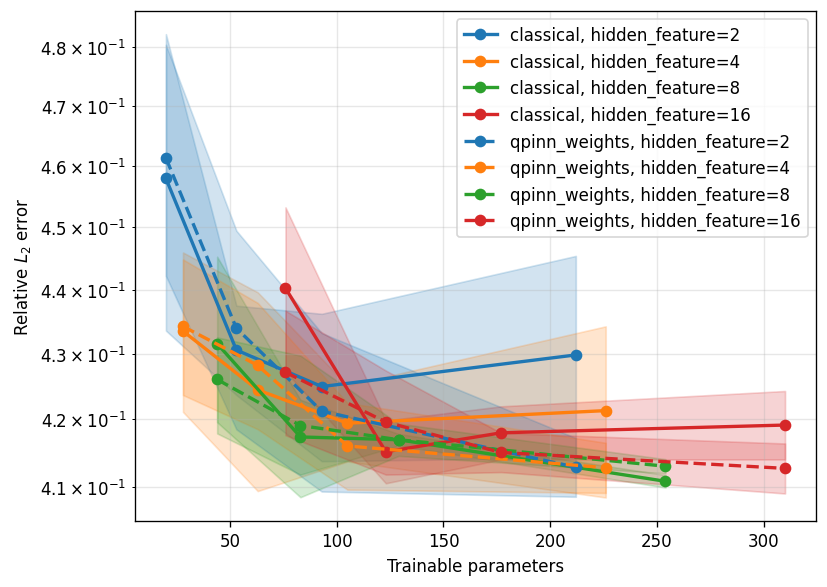

FREQ=1.5


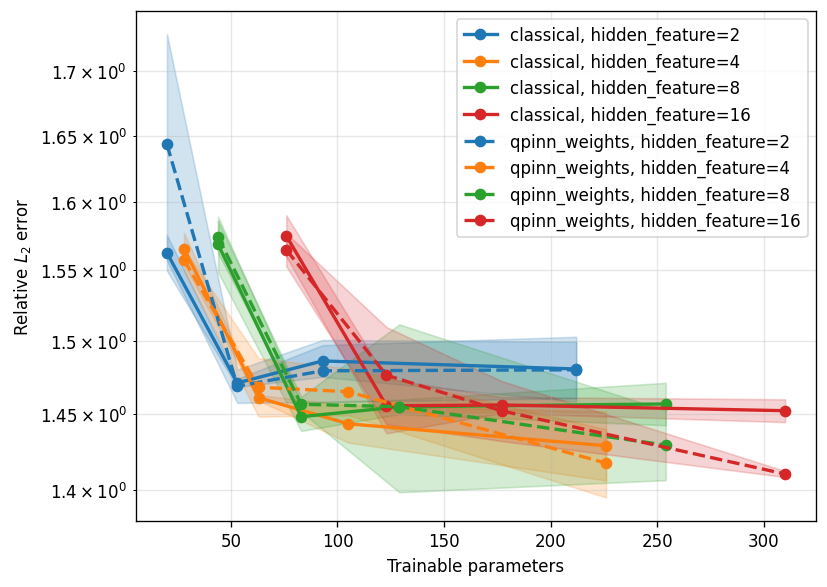

FREQ=3.0


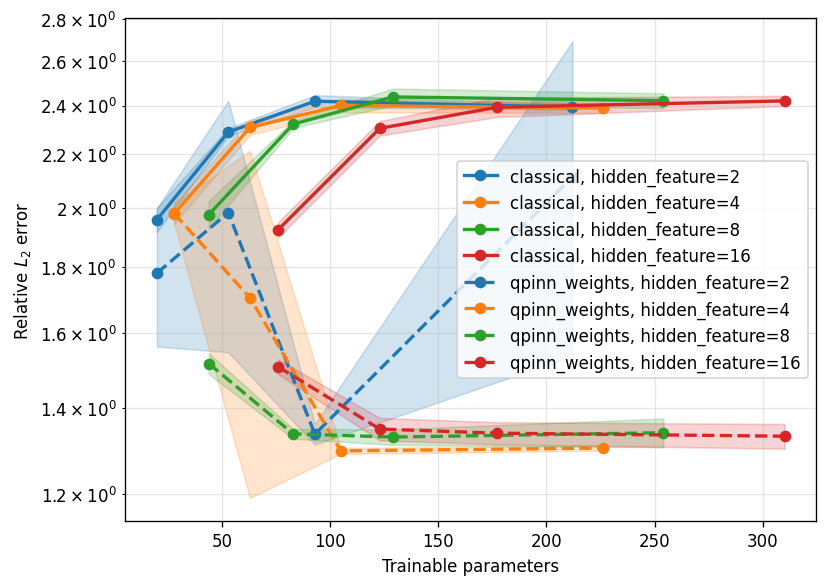

In [62]:
%reload_ext autoreload
import matplotlib.pyplot as plt

def plot_weight_sweep(
    sweep_results,
    save_path=None,
    show=True,
):
    fig, ax = plt.subplots(figsize=(7, 5))

    colors = plt.cm.tab10.colors

    for model_name, linestyle in [
        ("classical", "-"),
        ("qpinn_weights", "--"),
    ]:

        # group results by hidden_feature
        hidden_features = sorted(
            {r["hidden_feature"] for r in sweep_results[model_name]}
        )

        for i, hf in enumerate(hidden_features):

            runs = [
                r for r in sweep_results[model_name]
                if r["hidden_feature"] == hf
            ]

            runs = sorted(runs, key=lambda x: x["num_weights"])

            x = np.array([r["num_weights"] for r in runs])
            y = np.array([np.mean(r["rel_l2"]) for r in runs])
            yerr = np.array([np.std(r["rel_l2"]) for r in runs])

            ax.plot(
                x,
                y,
                linestyle,
                color=colors[i % len(colors)],
                marker="o",
                linewidth=2,
                label=f"{model_name}, hidden_feature={hf}",
            )

            ax.fill_between(
                x,
                y - yerr,
                y + yerr,
                color=colors[i % len(colors)],
                alpha=0.2,
            )

    ax.set_yscale("log")
    ax.set_xlabel("Trainable parameters")
    ax.set_ylabel("Relative $L_2$ error")

    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close()

print(full_sweep_results)

#for freq_dict in full_sweep_results:
#
#    freq = next(iter(freq_dict))
#    sweep_results = freq_dict[freq]
#
#    hidden_features = sorted(
#        {r["hidden_feature"] for r in sweep_results["classical"]}
#    )
#
#    for hf in hidden_features:
#
#        filtered = {
#            "classical": [
#                r for r in sweep_results["classical"]
#                if r["hidden_feature"] == hf
#            ],
#            "qpinn_weights": [
#                r for r in sweep_results["qpinn_weights"]
#                if r["hidden_feature"] == hf
#            ],
#        }
#
#        plot_weight_sweep(
#            filtered,
#            save_path=f"figures/fourier_demo/weight_sweep_freq={freq:g}_hf={hf}.png",
#            show=True,
#        )

for freq_id in range(len(FREQUENCIES)):
    print(f"FREQ={FREQUENCIES[freq_id]}")
    plot_weight_sweep(
        full_sweep_results[freq_id][FREQUENCIES[freq_id]],
        save_path=f"figures/fourier_demo/weight_sweep_freq={FREQUENCIES[freq_id]}.png",
    )



#plot_frequency_sweep(
#    sweep_results,
#    save_path = "figures/fourier_demo/weights_sweep_freq=3.5.png",
#    show      = True,
#    label     = 'Weights',
#)

## 2 - Train both models with same frequency and compare

In [ ]:
FREQUENCY = 3.0

In [ ]:

ref_pde = HeatEquation(freq=FREQUENCY)

# QPINN
qpinn_ref = MerlinHeatQPINN().to(device)
history_q = train(model=qpinn_ref, pde=ref_pde, epochs = 600)

# Classical
classical_ref = ClassicalHeatQPINN().to(device)
history_c = train(model=classical_ref, pde=ref_pde, epochs = 600)

qpinn_weights_ref = MerlinTunableSimple().to(device)
history_qpinn_weights = train(model=qpinn_weights_ref, pde=ref_pde, epochs = 600)

In [ ]:
# Evaluate models
grid_n = 60


_, U_pred_q, U_true, x_grid, t_grid = evaluate(model=qpinn_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_c, _,      _,      _      = evaluate(model=classical_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_q_w, _,      _,      _      = evaluate(model=qpinn_weights, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

#TODO : figure out here Q error is smaller than C error ??? this doesnt match results from other pipeline

In [ ]:
plot_solution_comparison(U_pred_q,U_true)
plot_solution_comparison(U_pred_c,U_true)
plot_solution_comparison(U_pred_q_w,U_true)


### 2.1 - Compare power spectra

In [ ]:
print("QPINN power spectrum")
plot_power_spectrum(U_pred_q, U_true, save_path="../figures/demo_fourier/power_spectrum_q.png", exclude_0_mode=False)

print("Classical power spectrum")
plot_power_spectrum(U_pred_c, U_true, save_path="../figures/demo_fourier/power_spectrum_c.png", exclude_0_mode=False)

### 2.2 Compare per-mode L2 error

In [ ]:
print("QPINN mode errors")
plot_mode_l2_errors(U_pred_q, U_true,
                    save_path="figures/fourier_demo/l2_error_Q.png")

print("Classical mode errors")
plot_mode_l2_errors(U_pred_c, U_true,
                    save_path="figures/fourier_demo/l2_error_C.png")

## Compare directly

In [ ]:


plot_multi_model_l2_error(U_true, [U_pred_q, U_pred_c],["Qpinn", "C PINN"])